In [1]:
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt

In [9]:
#测试使用sympy
x,y = smp.symbols('x y') #定义变量
smp.diff(1/(1+smp.exp(-x)))  #测试sigmod函数
smp.integrate((-1)**x,x)

-(-1)**x*I/pi

In [6]:
x,y = smp.symbols('x y') #定义变量
#微分导数计算：
smp.diff(((1 + smp.sin(x))/(1-smp.cos(x)))**2,x)


f,g = smp.symbols('f g',cls=smp.Function)
g = g(x)
f = f(x+g)
dfdx = smp.diff(f,x)
dfdx.subs([(g,smp.sin(x))]).doit() #doit()函数表示 计算最后的结果

(cos(x) + 1)*Subs(Derivative(f(_xi_1), _xi_1), _xi_1, x + sin(x))

In [62]:
# 积分,不定积分
smp.integrate(smp.csc(x)*smp.cot(x),x)
smp.integrate(smp.exp(x)/smp.sqrt(smp.exp(2*x) + 9 ),(x,0,smp.log(4)))

t = smp.symbols('t')
smp.integrate(x**10*smp.exp(x),(x,1,t))

(t**10 - 10*t**9 + 90*t**8 - 720*t**7 + 5040*t**6 - 30240*t**5 + 151200*t**4 - 604800*t**3 + 1814400*t**2 - 3628800*t + 3628800)*exp(t) - 1334961*E

In [4]:
#定义变量
x,y = smp.symbols('x,y')
#使用变量进行数学表达式和函数表达
x**2
smp.sin(x)

sin(x)

In [14]:
x,y = smp.symbols('x,y')
#因式分解：
z = (x**2 + 4*x+ 3)**2
z.factor()
#因式展开
z.expand()

#求解方程式smp.solve(f,x)
smp.solve(z,x)
print(smp.solve(x**2+1,x))
#定义变量 x 为实数范围，然后就没有实数域的解了
x = smp.symbols('x',real=True, positive=True)
print(smp.solve(x**2+1,x))

# 返回一个多项式对象
z.as_poly()




[-I, I]
[]


Poly(x**4 + 8*x**3 + 22*x**2 + 24*x + 9, x, domain='ZZ')

3.6651914291880887

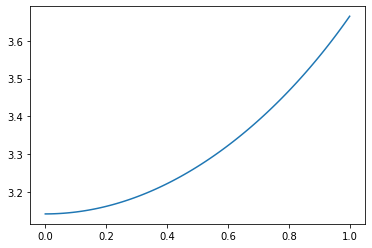

In [22]:
#lambdify 的使用样例
expr = smp.asin(x**2/y) + np.pi
expr_f = smp.lambdify((x,y),expr)
x_num = np.linspace(0,1, 100)
y_num = 2
plt.plot(x_num,expr_f(x_num,y_num))

expr_f(1,2)

In [38]:
x,y,z = smp.symbols('x,y,z')
F = x**2 + y*smp.sin(z)
expr_f = smp.lambdify((x,y,z),F)
#替换表达式中变量为值
# F.subs([(y,3),(z,smp.pi/2)])
F.subs([(y,smp.cos(z)),(z,smp.pi/2)])

#表示几分之几
smp.Rational(1,2)
F

x**2 + y*sin(z)

In [31]:
#实现一个物体落地的模拟
t,h0,v0,g,vp,q = smp.symbols('t h_0 v_0 g v_p q',real=True,positive=True)

h0t = h0 - v0*t - smp.Rational(1,2)*g*t**2
dh0dt = g*t - v0
hpt = vp*t + smp.Rational(1,2)*q*t**2
dhpdt = vp+q*t


In [33]:
eq1 = h0t - hpt
eq2 = dh0dt + dhpdt


In [34]:
t_collide,v_initfall = smp.solve([eq1,eq2],[t,v0])[0]

-g*t**2/2 + h_0 - q*t**2/2 - t*v_0 - t*v_p

In [35]:
smp.solve([eq1,eq2],[t,v0])

[((-2*v_p/3 + sqrt(2)*sqrt(3*g*h_0 + 3*h_0*q + 2*v_p**2)/3)/(g + q),
  v_p/3 + sqrt(2)*sqrt(3*g*h_0 + 3*h_0*q + 2*v_p**2)/3)]

In [58]:
#极限的表达
x,y = smp.symbols('x y')
expr = smp.sin(x/2 + smp.sin(x))
smp.limit(expr,x,smp.pi)

1

In [69]:
from sympy import assoc_laguerre
r,a  = smp.symbols('r a',real=True,positive=True)
n,l  = smp.symbols('n l',integer=True,positive=True)
R = smp.sqrt((2/(n*a))**3 * smp.factorial(n-l-1)/(2*n*(smp.factorial(n+l)))) \
    * smp.exp(-r/(n*a)) * (2*r/(n*a))**l * assoc_laguerre(n-l-1,2*l+1 ,(2*r/(n*a)))
R

2*(2*r/(a*n))**l*exp(-r/(a*n))*assoc_laguerre(-l + n - 1, 2*l + 1, 2*r/(a*n))*sqrt(factorial(-l + n - 1))/(a**(3/2)*n**2*sqrt(factorial(l + n)))

In [78]:
R_10 = R.subs([(n,4),(l,3)])
R_10

sqrt(35)*r**3*exp(-r/(4*a))/(26880*a**(9/2))

In [81]:
def compute_int(n_val,l_val,k):
    R_nl = R.subs([(n,n_val),(l,l_val)])
    return smp.integrate(R_nl**2*r**k,(r,0,smp.oo))
compute_int(n_val=3,l_val=1,k=3)

25*a/2

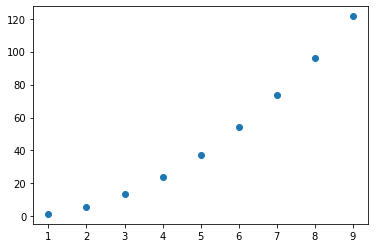

In [84]:
def compute_mean_distance(n_val,l_val=0):
    expr = compute_int(n_val,l_val,k=3)
    expr_f = smp.lambdify([a],expr)
    return expr_f(1)

ns = np.arange(1,10)
ds = [compute_mean_distance(ni) for ni in ns]
plt.scatter(ns,ds)


In [89]:
#向量和几何
x,y,z,u1,u2,u3,v1,v2,v3,t = smp.symbols('x y z u_1 u_2 u_3 v_1 v_2 v_3 t')
u = smp.Matrix([u1,u2,u3])
v = smp.Matrix([v1,v2,v3])
2*u+v
u.dot(v)
u.cross(v)
u.norm()




sqrt(Abs(u_1)**2 + Abs(u_2)**2 + Abs(u_3)**2)

$proj_v\left(u\right) = {u\cdot v\over |v|^2} \cdot v $


In [91]:
#上面的公式就是投影向量
proj_v_u = u.dot(v)/v.norm()**2  * v
proj_v_u

Matrix([
[v_1*(u_1*v_1 + u_2*v_2 + u_3*v_3)/(Abs(v_1)**2 + Abs(v_2)**2 + Abs(v_3)**2)],
[v_2*(u_1*v_1 + u_2*v_2 + u_3*v_3)/(Abs(v_1)**2 + Abs(v_2)**2 + Abs(v_3)**2)],
[v_3*(u_1*v_1 + u_2*v_2 + u_3*v_3)/(Abs(v_1)**2 + Abs(v_2)**2 + Abs(v_3)**2)]])

In [95]:
#向量求导
r = smp.Matrix([3*t,smp.sin(t),t**2])
# smp.diff(r,t)
v = smp.diff(r,t)
a = smp.diff(v,t)
theta = smp.acos(v.dot(a)/(v.norm()*a.norm())).simplify()
theta

acos((4*t - sin(2*t)/2)/(sqrt(Abs(sin(t))**2 + 4)*sqrt(4*Abs(t)**2 + Abs(cos(t))**2 + 9)))

In [97]:
theta.subs(t,6).evalf() #evalf() 用于计算smp 表达式的值

0.251108015692338

In [107]:
#向量积分
r = smp.Matrix([smp.exp(t)*smp.cos(t),t**4,1/(1+t**2)])
smp.Integral(r,t).doit()


Matrix([
[exp(t)*sin(t)/2 + exp(t)*cos(t)/2],
[                           t**5/5],
[                          atan(t)]])

Matrix([
[exp(t)*sin(t)/2 + exp(t)*cos(t)/2],
[                           t**5/5],
[                          atan(t)]])